# Data Preprocessing Workflow

Preprocess `dataset/data.csv` including: handling missing values, encoding non-numeric data, preliminary statistical analysis, and visualization.

Ablation outputs:
- Original preprocessing workflow with the Section 4 encoding method: `data/processed_org/{train,val,test}.csv`
- Split-first preprocessing workflow with train-only imputation statistics and `pd.get_dummies`: `data/processed/{train,val,test}.csv`

## 1. Import packages

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 100
print("Libraries loaded successfully.")

Libraries loaded successfully.


## 2. Load CSV raw data


Due to the large size, use `nrows`, read 5 lines to preview the structure, and then load the entire dataset to preprocess. 

In [2]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "preprocess" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "dataset" / "data.csv"
OUTPUT_PATH = PROJECT_ROOT / "dataset" / "processed_data.csv"
ORG_OUTPUT_DIR = PROJECT_ROOT / "data" / "processed_org"
ALT_OUTPUT_DIR = PROJECT_ROOT / "data" / "processed"

# Use nrows for preview
preview = pd.read_csv(DATA_PATH, sep=';', nrows=5)
print(f"Raw data path: {DATA_PATH}")
print(f"Rows: {preview.shape[0]},  Columns: {preview.shape[1]}")
print("\nColumn names:")
print(list(preview.columns))
preview

Raw data path: f:\2026_spring_project\2011_project\dataset\data.csv
Rows: 5,  Columns: 37

Column names:
['Marital status', 'Application mode', 'Application order', 'Course', 'Daytime/evening attendance\t', 'Previous qualification', 'Previous qualification (grade)', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Admission grade', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment', 'International', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular 

,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [3]:
# Load the full dataset
df = pd.read_csv(DATA_PATH, sep=';')
print(f"Dataset shape: {df.shape}")
print(f"\nData types:\n{df.dtypes}")

Dataset shape: (4424, 37)

Data types:
Marital status                                      int64
Application mode                                    int64
Application order                                   int64
Course                                              int64
Daytime/evening attendance\t                        int64
Previous qualification                              int64
Previous qualification (grade)                    float64
Nacionality                                         int64
Mother's qualification                              int64
Father's qualification                              int64
Mother's occupation                                 int64
Father's occupation                                 int64
Admission grade                                   float64
Displaced                                           int64
Educational special needs                           int64
Debtor                                              int64
Tuition fees up to date          

## 3. Handling Missing Values

In [4]:
# Count missing values and their proportions for each column
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({"Missing Count": missing, "Missing Percentage (%)": missing_pct})
missing_df = missing_df[missing_df["Missing Count"] > 0].sort_values("Missing Percentage (%)", ascending=False)

if missing_df.empty:
    print("No missing values in the dataset.")
else:
    print(f"Columns with missing values (total {len(missing_df)} columns):")
    print(missing_df)

No missing values in the dataset.


In [5]:
DROP_THRESHOLD = 50.0  # Drop columns if missing rate exceeds this threshold

# Remove columns with high missing rates
cols_to_drop = missing_df[missing_df["Missing Percentage (%)"] > DROP_THRESHOLD].index.tolist()
if cols_to_drop:
    df.drop(columns=cols_to_drop, inplace=True)
    print(f"Dropped columns with missing rate > {DROP_THRESHOLD}%: {cols_to_drop}")

# Fill numeric columns with median, categorical columns with mode
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()

for col in num_cols:
    if df[col].isnull().any():
        median_val = df[col].median()
        df[col].fillna(median_val, inplace=True)
        print(f"  Numeric column '{col}': filled missing values with median {median_val:.4f}")

for col in cat_cols:
    if df[col].isnull().any():
        mode_val = df[col].mode()[0]
        df[col].fillna(mode_val, inplace=True)
        print(f"  Categorical column '{col}': filled missing values with mode '{mode_val}'")

print(f"\nTotal missing values after processing: {df.isnull().sum().sum()}")


Total missing values after processing: 0


## 4. Handling Non-Numeric Data

Identify all string/categorical columns, apply `LabelEncoder` for encoding, and record the mappings.

In [6]:
# Re-detect non-numeric columns (may change after handling missing values)
cat_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()
print(f"Non-numeric columns: {cat_cols}")

label_encoders = {}
label_mappings = {}

for col in cat_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col].astype(str))
    label_encoders[col] = le
    label_mappings[col] = dict(zip(le.classes_, le.transform(le.classes_)))
    print(f"\nColumn '{col}' encoding mapping: {label_mappings[col]}")

print("\nEncoding completed. All columns are now numeric.")
print(f"Dataset shape: {df.shape}")

Non-numeric columns: ['Target']

Column 'Target' encoding mapping: {'Dropout': 0, 'Enrolled': 1, 'Graduate': 2}

Encoding completed. All columns are now numeric.
Dataset shape: (4424, 37)


## 5. Preliminary Statistical Analysis

In [7]:
# Descriptive statistics (mean, variance, std, quantiles, etc.)
stats = df.describe().T
stats["variance"] = df.var()
stats["skewness"] = df.skew()
stats["kurtosis"] = df.kurtosis()
stats = stats[["count", "mean", "variance", "std", "min", "25%", "50%", "75%", "max", "skewness", "kurtosis"]]
stats.columns = ["Count", "Mean", "Variance", "Std Dev", "Min", "Q1", "Median", "Q3", "Max", "Skewness", "Kurtosis"]
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.4f}".format)
stats

,Count,Mean,Variance,Std Dev,Min,Q1,Median,Q3,Max,Skewness,Kurtosis
Marital status,4424.0000,1.1786,0.3669,0.6057,1.0000,1.0000,1.0000,1.0000,6.0000,4.3998,21.4826
Application mode,4424.0000,18.6691,305.7141,17.4847,1.0000,1.0000,17.0000,39.0000,57.0000,0.3930,-1.4538
Application order,4424.0000,1.7278,1.7261,1.3138,0.0000,1.0000,1.0000,2.0000,9.0000,1.8810,2.6513
Course,4424.0000,8856.6426,4258306.3541,2063.5664,33.0000,9085.0000,9238.0000,9556.0000,9991.0000,-3.8091,13.1991
Daytime/evening attendance\t,4424.0000,0.8908,0.0973,0.3119,0.0000,1.0000,1.0000,1.0000,1.0000,-2.5072,4.2882
Previous qualification,4424.0000,4.5778,104.3788,10.2166,1.0000,1.0000,1.0000,1.0000,43.0000,2.8712,6.7782
Previous qualification (grade),4424.0000,132.6133,173.9321,13.1883,95.0000,125.0000,133.1000,140.0000,190.0000,0.3129,0.9683
Nacionality,4424.0000,1.8732,47.8105,6.9145,1.0000,1.0000,1.0000,1.0000,109.0000,10.7040,135.1462
Mother's qualification,4424.0000,19.5619,243.4594,15.6032,1.0000,2.0000,19.0000,37.0000,44.0000,0.0020,-1.6923
Father's qualification,4424.0000,22.2753,235.4110,15.3431,1.0000,3.0000,19.0000,37.0000,44.0000,-0.2987,-1.5806


In [8]:
# Correlation matrix (sorted by absolute value, display top 10 features with highest correlation to Target)
corr_matrix = df.corr()
if "Target" in corr_matrix.columns:
    target_corr = corr_matrix["Target"].drop("Target").abs().sort_values(ascending=False)
    print("Top 10 features with highest correlation to Target:")
    print(target_corr.head(10))

Top 10 features with highest correlation to Target:
Curricular units 2nd sem (approved)   0.6242
Curricular units 2nd sem (grade)      0.5668
Curricular units 1st sem (approved)   0.5291
Curricular units 1st sem (grade)      0.4852
Tuition fees up to date               0.4098
Scholarship holder                    0.2976
Age at enrollment                     0.2434
Debtor                                0.2410
Gender                                0.2293
Application mode                      0.2217
Name: Target, dtype: float64


## 6. Data Distribution Visualization

Continuous features for plotting (21 columns): ['Application mode', 'Course', 'Previous qualification', 'Previous qualification (grade)', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Admission grade', 'Age at enrollment', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)']


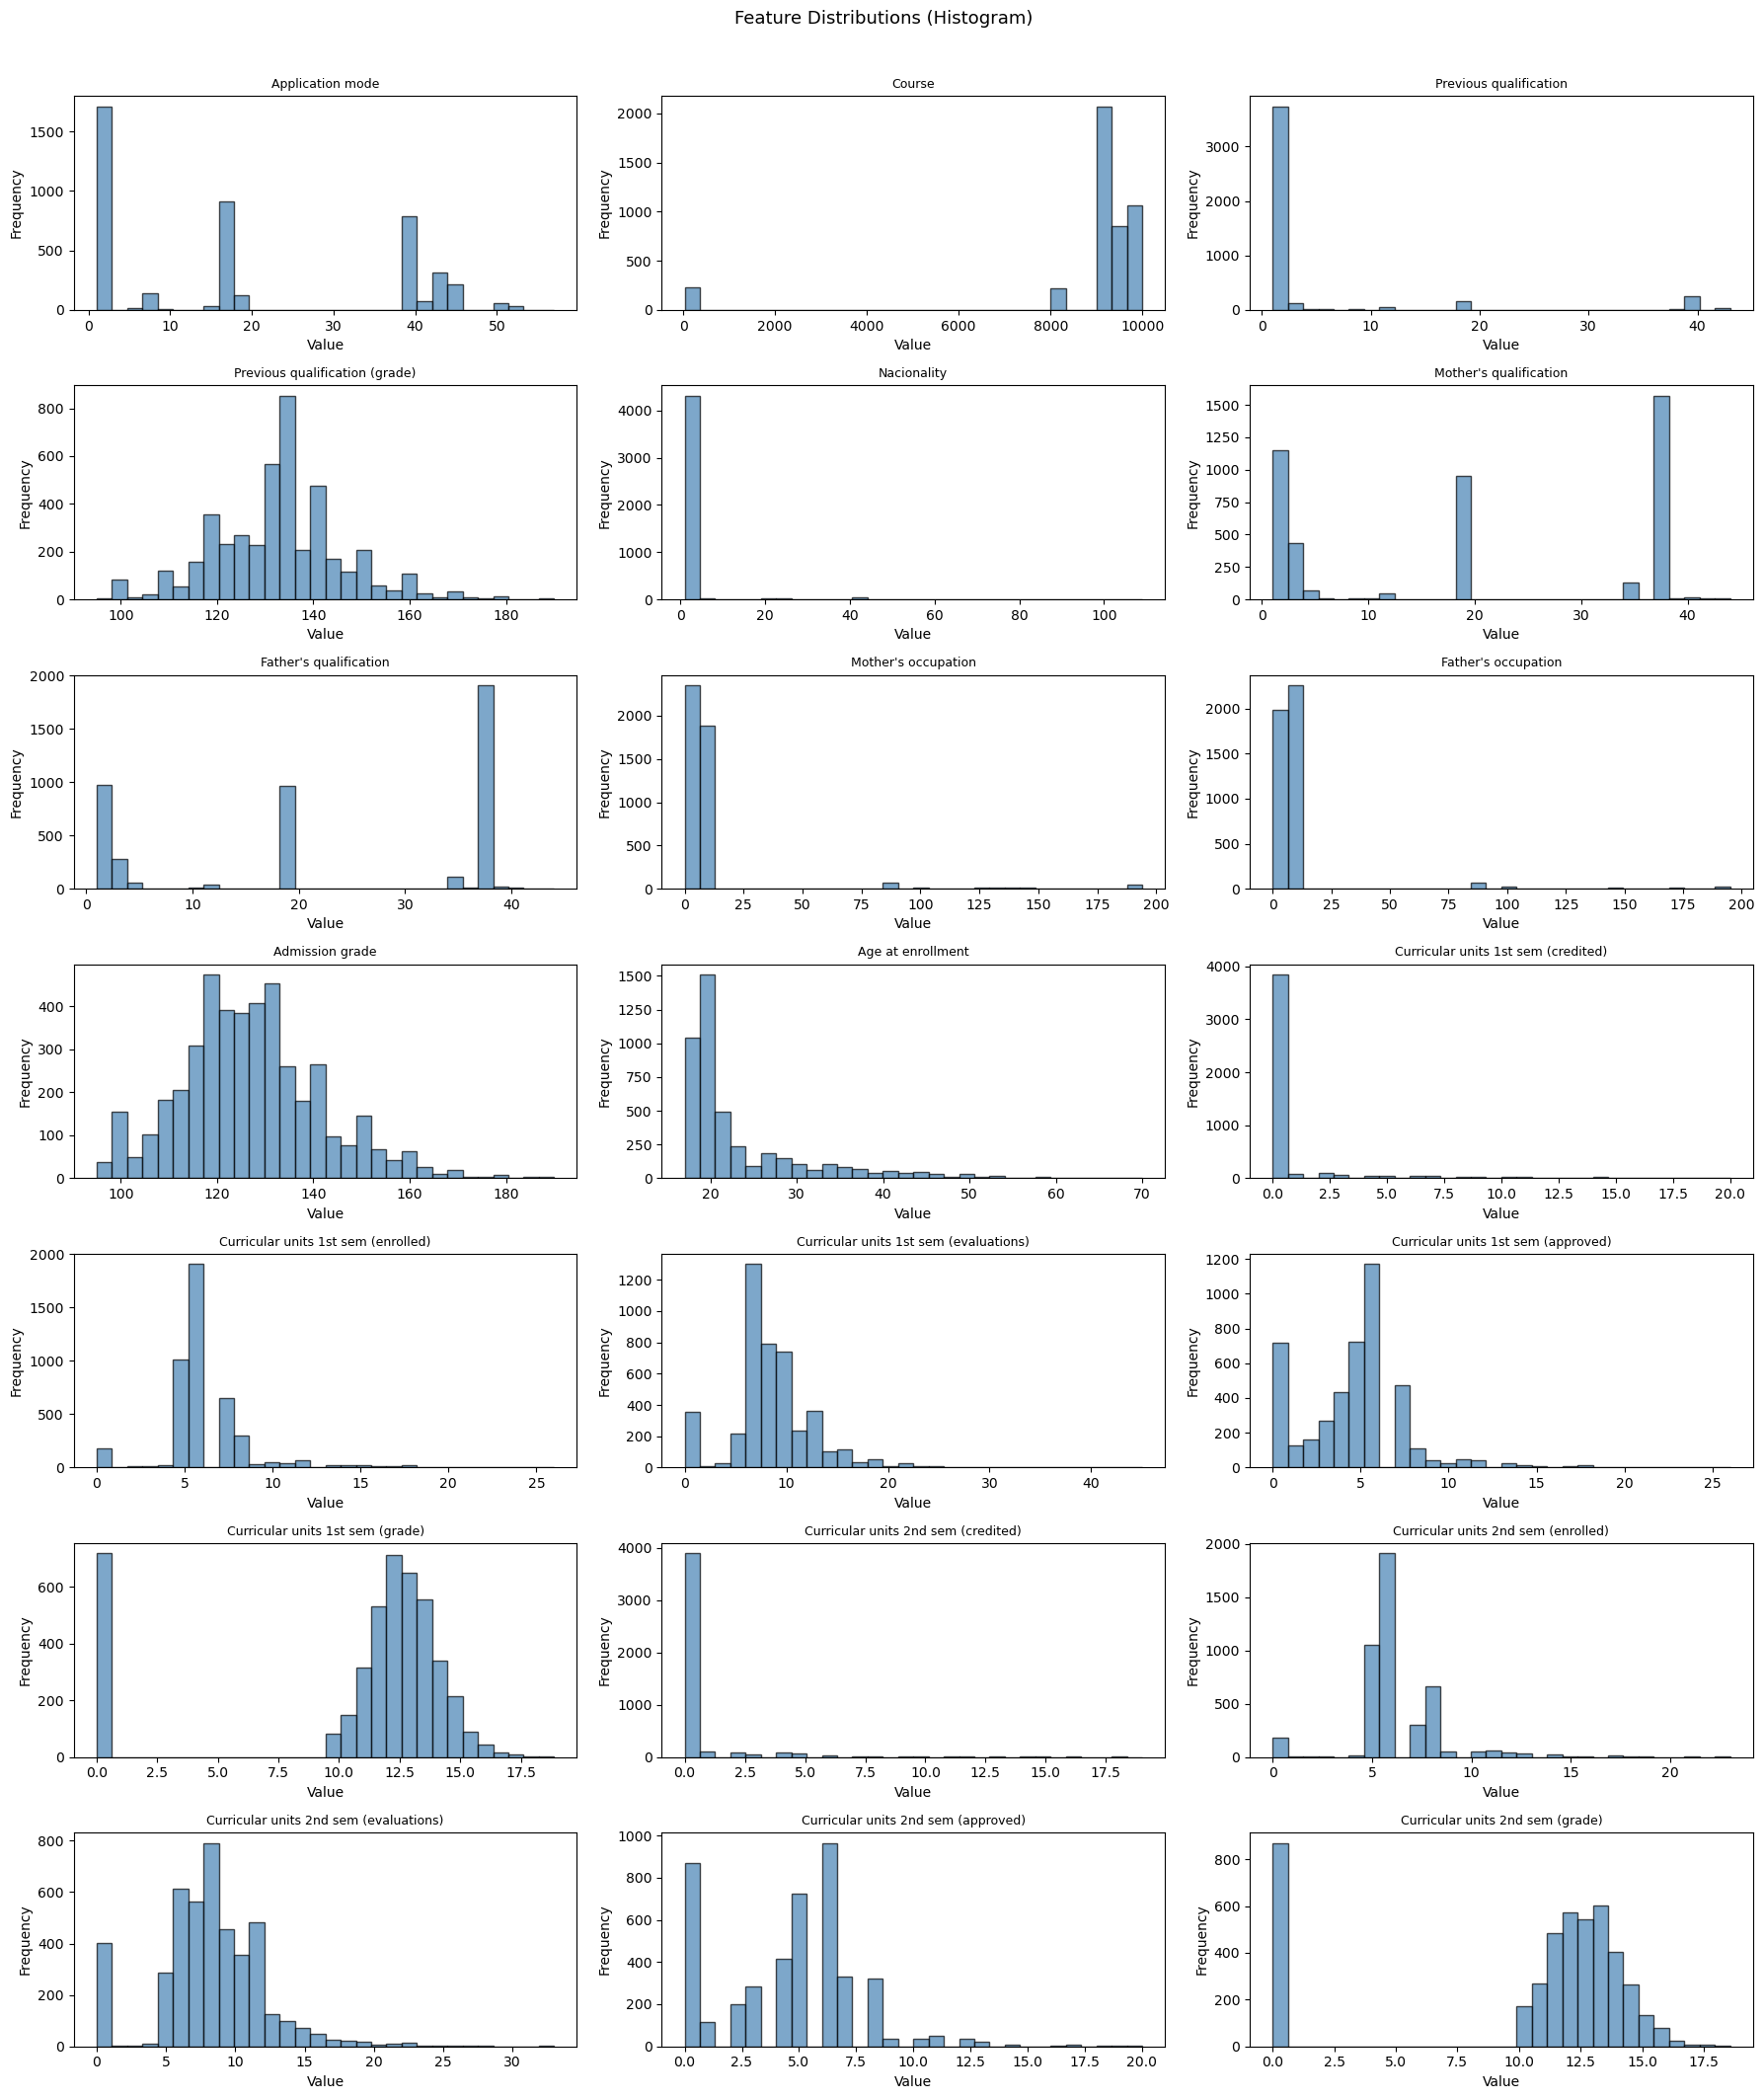

In [9]:
# Select continuous numeric features (treat low-cardinality columns as categorical, skip them)
CARDINALITY_THRESHOLD = 15
continuous_cols = [c for c in df.columns if df[c].nunique() > CARDINALITY_THRESHOLD]
print(f"Continuous features for plotting ({len(continuous_cols)} columns): {continuous_cols}")

# Histogram
n = len(continuous_cols)
if n > 0:
    ncols = 3
    nrows = (n + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(18, nrows * 3))
    axes = axes.flatten()
    for i, col in enumerate(continuous_cols):
        axes[i].hist(df[col].dropna(), bins=30, edgecolor='black', color='steelblue', alpha=0.7)
        axes[i].set_title(f"{col}", fontsize=9)
        axes[i].set_xlabel("Value")
        axes[i].set_ylabel("Frequency")
    for j in range(i + 1, len(axes)):
        axes[j].set_visible(False)
    plt.suptitle("Feature Distributions (Histogram)", fontsize=13, y=1.01)
    plt.tight_layout()
    plt.show()

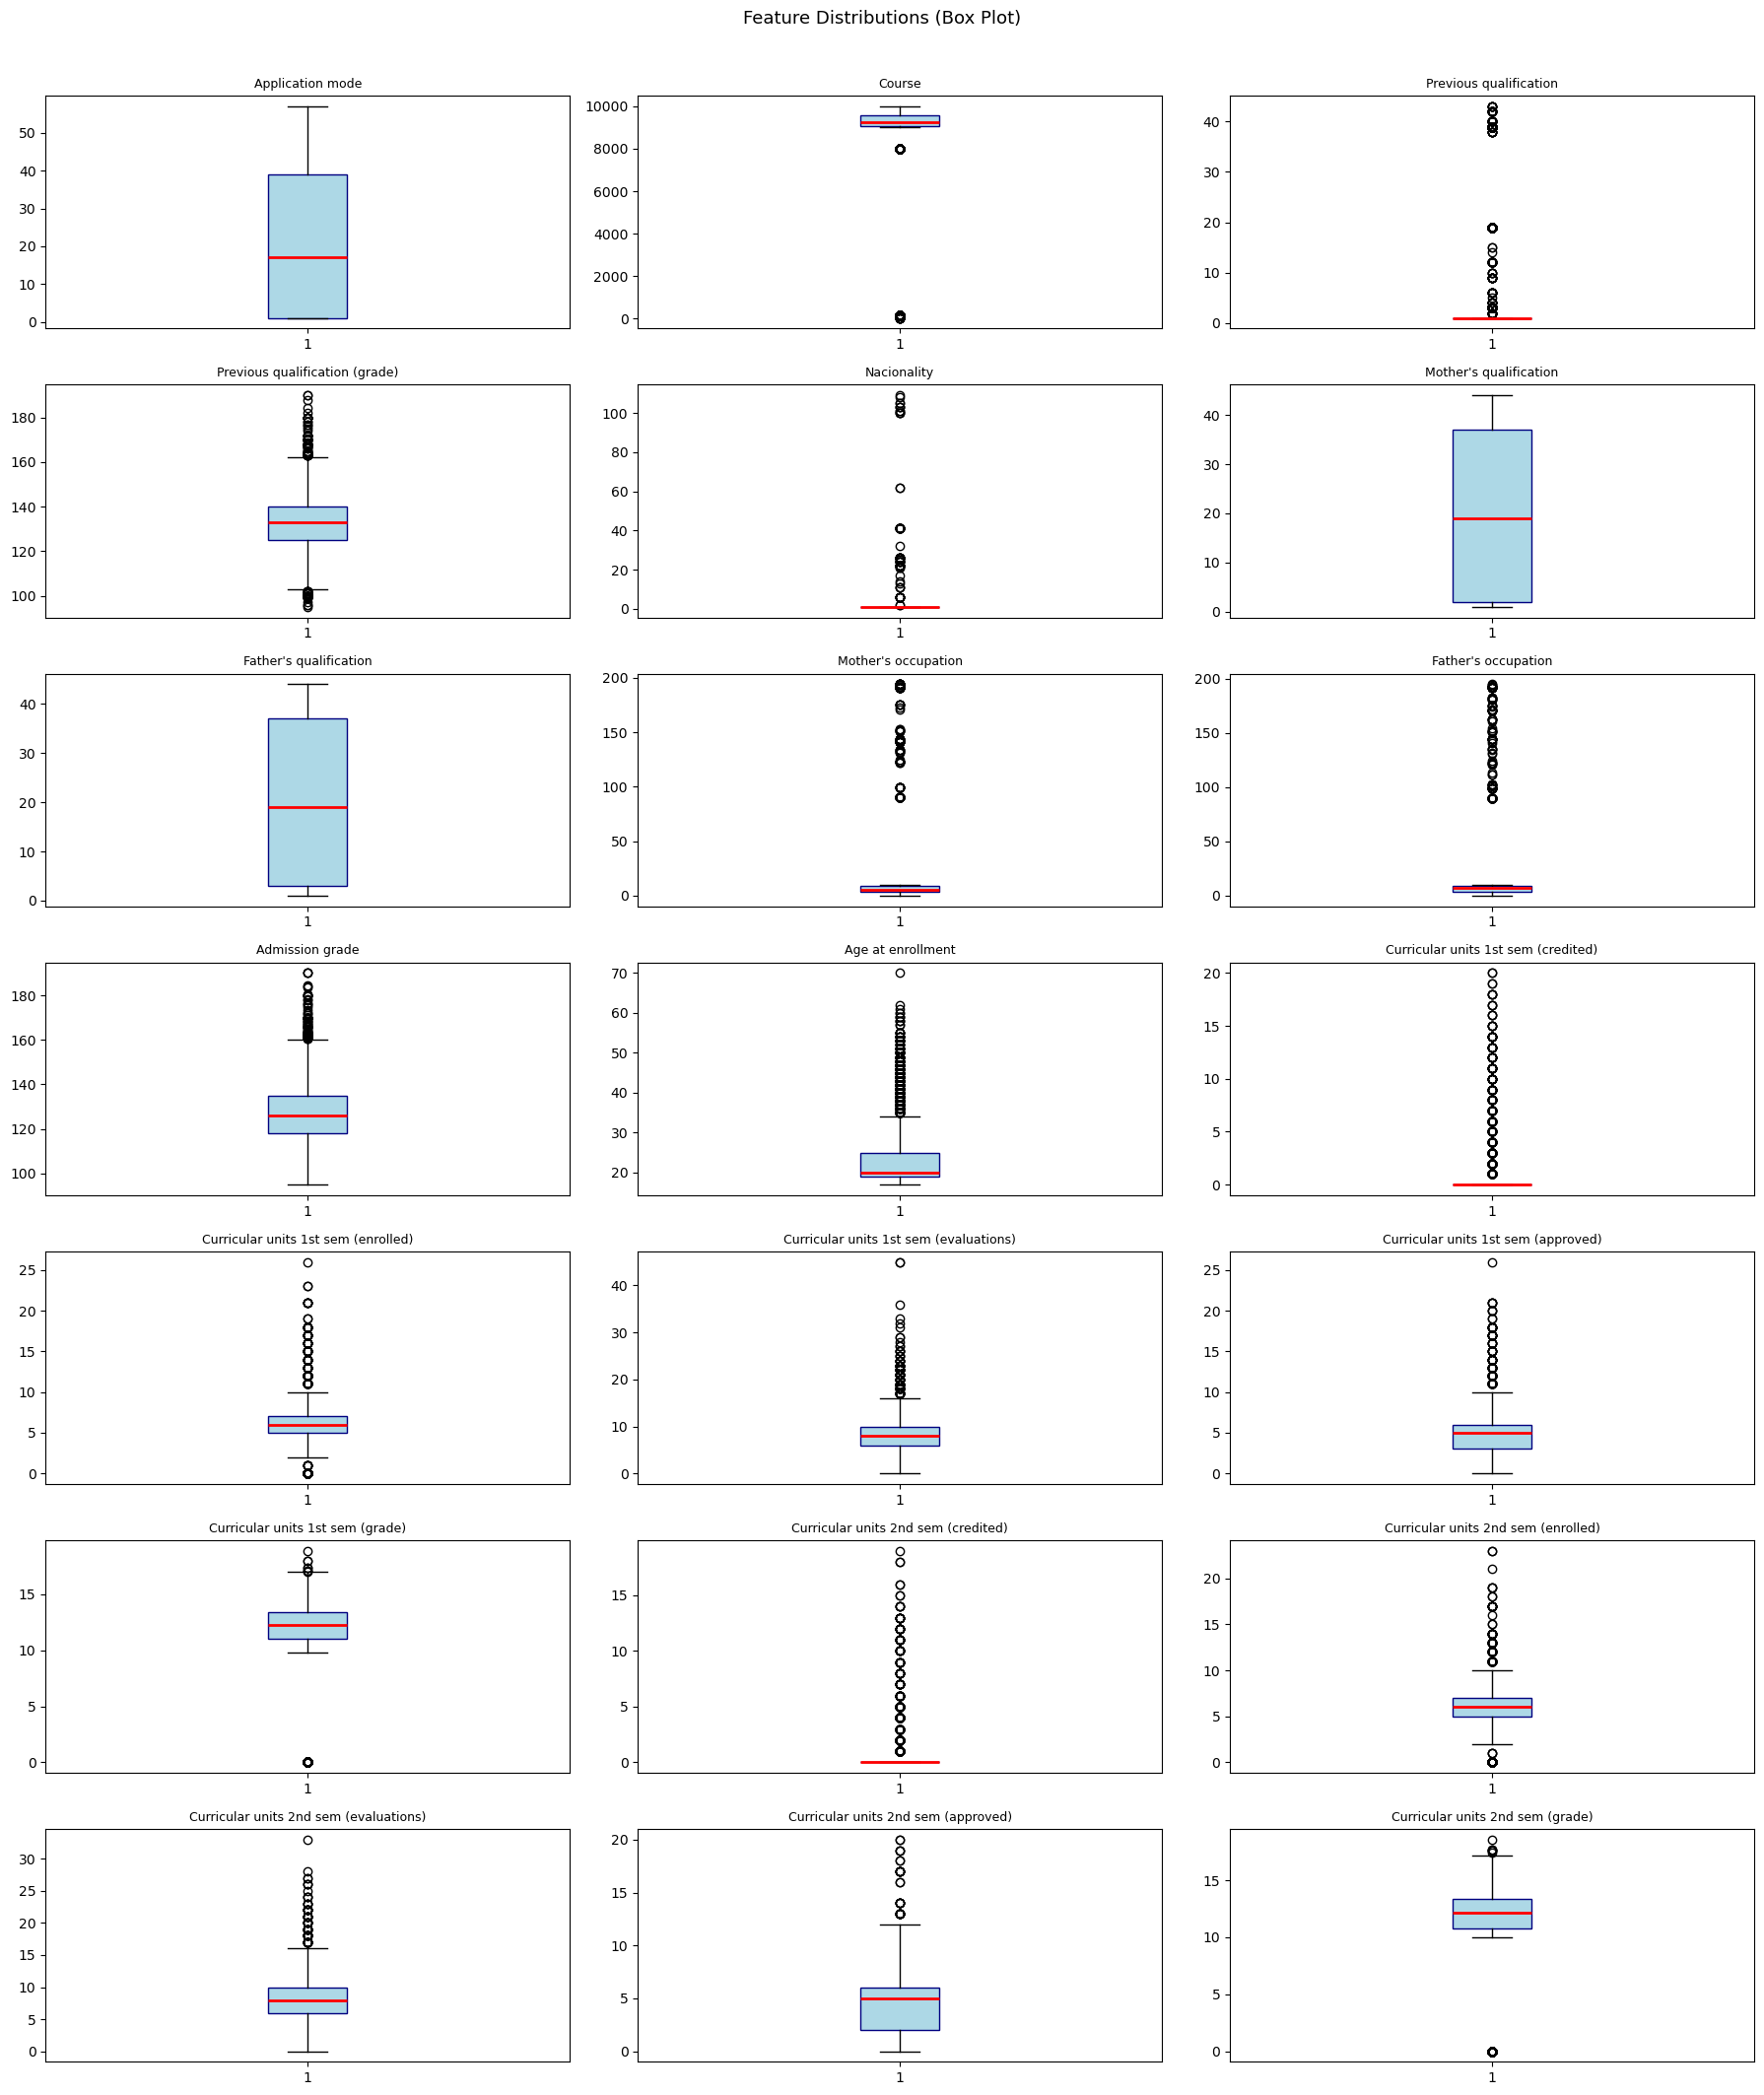

In [10]:
# Box plot (to visualize outliers)
if n > 0:
    fig, axes = plt.subplots(nrows, ncols, figsize=(18, nrows * 3))
    axes = axes.flatten()
    for i, col in enumerate(continuous_cols):
        axes[i].boxplot(df[col].dropna(), vert=True, patch_artist=True,
                        boxprops=dict(facecolor='lightblue', color='navy'),
                        medianprops=dict(color='red', linewidth=2))
        axes[i].set_title(f"{col}", fontsize=9)
    for j in range(i + 1, len(axes)):
        axes[j].set_visible(False)
    plt.suptitle("Feature Distributions (Box Plot)", fontsize=13, y=1.01)
    plt.tight_layout()
    plt.show()

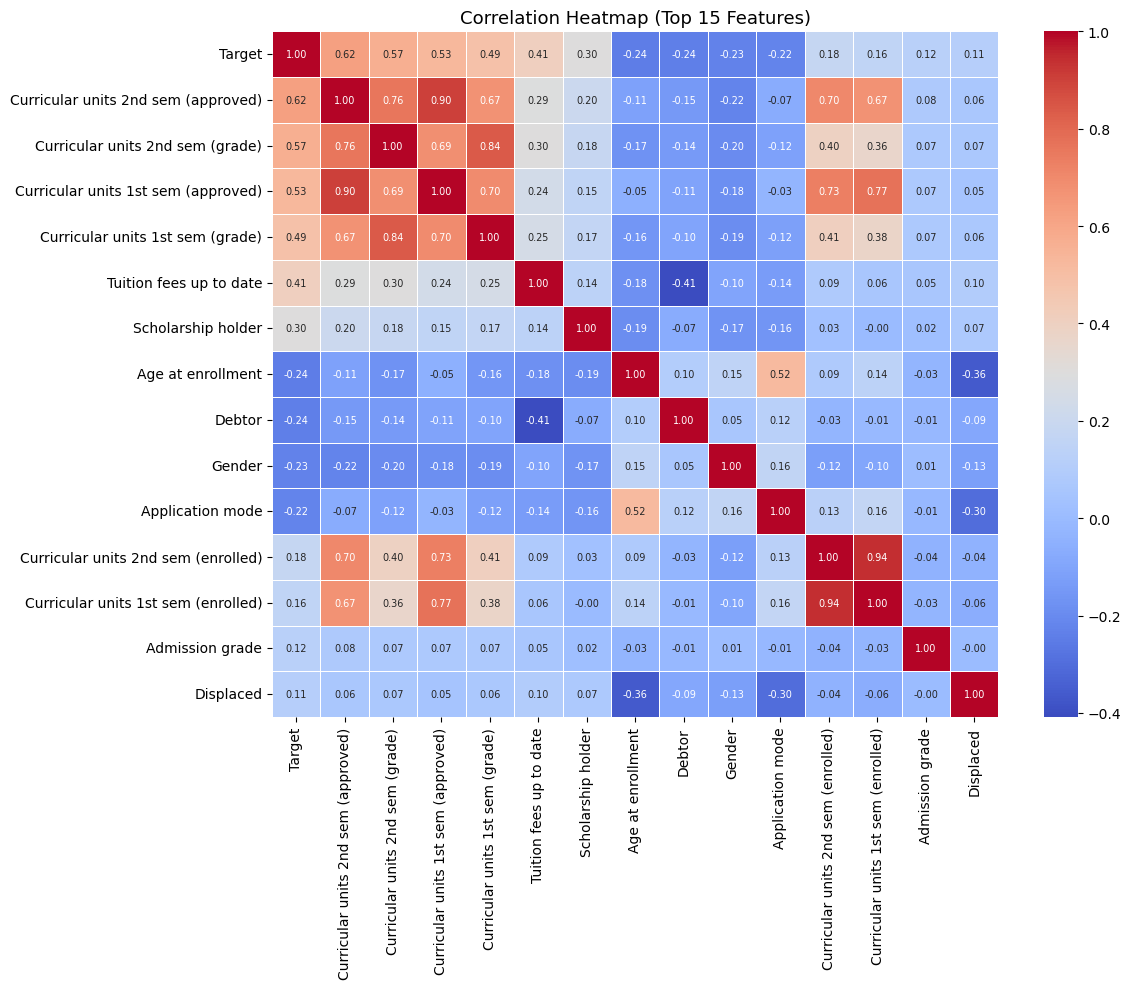

In [11]:
# Correlation heatmap (display top 15 features with highest correlation to Target)
top_features = corr_matrix["Target"].abs().sort_values(ascending=False).head(15).index.tolist() \
    if "Target" in corr_matrix.columns else list(df.columns[:15])

corr_sub = df[top_features].corr()
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr_sub, annot=True, fmt=".2f", cmap="coolwarm",
            linewidths=0.5, ax=ax, annot_kws={"size": 7})
ax.set_title("Correlation Heatmap (Top 15 Features)", fontsize=13)
plt.tight_layout()
plt.show()

## 7. Export Processed Data

In [12]:
from sklearn.model_selection import train_test_split

ORIGINAL_VAL_SIZE = 0.15
ORIGINAL_TEST_SIZE = 0.15
ORIGINAL_RANDOM_STATE = 42

original_stratify = df["Target"] if "Target" in df.columns else None
org_train_df, org_holdout_df = train_test_split(
    df,
    test_size=ORIGINAL_VAL_SIZE + ORIGINAL_TEST_SIZE,
    random_state=ORIGINAL_RANDOM_STATE,
    stratify=original_stratify,
    shuffle=True,
    )

org_holdout_test_ratio = ORIGINAL_TEST_SIZE / (ORIGINAL_VAL_SIZE + ORIGINAL_TEST_SIZE)
org_holdout_stratify = org_holdout_df["Target"] if "Target" in org_holdout_df.columns else None
org_val_df, org_test_df = train_test_split(
    org_holdout_df,
    test_size=org_holdout_test_ratio,
    random_state=ORIGINAL_RANDOM_STATE,
    stratify=org_holdout_stratify,
    shuffle=True,
    )

os.makedirs(ORG_OUTPUT_DIR, exist_ok=True)
org_train_df.to_csv(ORG_OUTPUT_DIR / "train.csv", index=False)
org_val_df.to_csv(ORG_OUTPUT_DIR / "val.csv", index=False)
org_test_df.to_csv(ORG_OUTPUT_DIR / "test.csv", index=False)

print("Original-method split sizes:")
print(f"  Train: {org_train_df.shape}")
print(f"  Val:   {org_val_df.shape}")
print(f"  Test:  {org_test_df.shape}")
print(f"Saved original-method splits under: {ORG_OUTPUT_DIR}")

org_train_df.head()

Original-method split sizes:
  Train: (3096, 37)
  Val:   (664, 37)
  Test:  (664, 37)
Saved original-method splits under: f:\2026_spring_project\2011_project\data\processed_org


,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
3742,1,17,1,9670,1,1,118.0000,1,19,38,7,9,113.5000,1,0,0,1,0,1,19,0,0,6,9,5,13.5000,0,0,6,6,6,14.0000,0,12.4000,0.5000,1.7900,2
3539,1,1,1,9070,1,1,139.0000,1,1,19,3,9,134.9000,1,0,0,1,1,0,20,0,0,6,7,6,13.6667,0,0,6,7,6,12.1667,1,16.2000,0.3000,-0.9200,2
1117,1,1,1,9500,1,1,138.0000,1,38,19,9,5,144.3000,0,0,0,1,0,0,20,0,0,7,9,6,12.7000,0,0,8,8,7,13.5714,0,13.9000,-0.3000,0.7900,2
790,1,17,1,9773,1,1,138.0000,1,1,19,9,9,124.0000,0,0,0,1,0,1,19,0,0,6,6,6,13.1667,0,0,6,6,6,13.8333,0,11.1000,0.6000,2.0200,2
4380,1,7,1,9500,1,2,140.0000,1,38,37,7,8,140.0000,0,0,0,1,0,0,29,0,0,8,14,4,11.3250,1,0,8,14,4,11.3250,1,12.7000,3.7000,-1.7000,0


## 8. Split-First Preprocessing With Train Statistics

Alternative preprocessing pipeline:
- Split the raw dataset into train/validation/test first.
- Compute missing-value fill parameters from the training split only.
- Apply the training fill parameters to validation and test.
- Use `pd.get_dummies` for one-hot encoding and align validation/test columns to the training feature space.

In [13]:
import os

import pandas as pd
from sklearn.model_selection import train_test_split

ALT_DATA_PATH = PROJECT_ROOT / "dataset" / "data.csv"
TARGET_COL = "Target"
VAL_SIZE = 0.15
TEST_SIZE = 0.15
RANDOM_STATE = 42
CATEGORICAL_COLUMNS = {
    "Marital status",
    "Application mode",
    "Application order",
    "Course",
    "Daytime/evening attendance",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation",
    "Displaced",
    "Educational special needs",
    "Debtor",
    "Tuition fees up to date",
    "Gender",
    "Scholarship holder",
    "International",
    }

raw_df = pd.read_csv(ALT_DATA_PATH, sep=';')
raw_df.columns = raw_df.columns.str.strip()
print(f"Raw dataset path: {ALT_DATA_PATH}")
print(f"Raw dataset shape: {raw_df.shape}")

stratify_labels = raw_df[TARGET_COL] if TARGET_COL in raw_df.columns else None
train_df, holdout_df = train_test_split(
    raw_df,
    test_size=VAL_SIZE + TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=stratify_labels,
    shuffle=True,
    )

holdout_test_ratio = TEST_SIZE / (VAL_SIZE + TEST_SIZE)
holdout_stratify = holdout_df[TARGET_COL] if TARGET_COL in holdout_df.columns else None
val_df, test_df = train_test_split(
    holdout_df,
    test_size=holdout_test_ratio,
    random_state=RANDOM_STATE,
    stratify=holdout_stratify,
    shuffle=True,
    )

feature_cols = [col for col in raw_df.columns if col != TARGET_COL]
categorical_cols = [col for col in feature_cols if col in CATEGORICAL_COLUMNS]
numeric_cols = [col for col in feature_cols if col not in categorical_cols]

numeric_fill_values = train_df[numeric_cols].median()
categorical_fill_values = {}
for col in categorical_cols:
    mode_values = train_df[col].mode(dropna=True)
    categorical_fill_values[col] = mode_values.iloc[0] if not mode_values.empty else "Missing"

def preprocess_split(split_df, train_feature_columns=None):
    features = split_df[feature_cols].copy()

    if numeric_cols:
        features.loc[:, numeric_cols] = features[numeric_cols].fillna(numeric_fill_values)

    for col, fill_value in categorical_fill_values.items():
        features[col] = features[col].fillna(fill_value)

    encoded_features = pd.get_dummies(features, columns=categorical_cols, dtype=int)

    if train_feature_columns is not None:
        encoded_features = encoded_features.reindex(columns=train_feature_columns, fill_value=0)

    return encoded_features

X_train = preprocess_split(train_df)
train_feature_columns = X_train.columns.tolist()
X_val = preprocess_split(val_df, train_feature_columns=train_feature_columns)
X_test = preprocess_split(test_df, train_feature_columns=train_feature_columns)

y_train = train_df[TARGET_COL].reset_index(drop=True) if TARGET_COL in train_df.columns else None
y_val = val_df[TARGET_COL].reset_index(drop=True) if TARGET_COL in val_df.columns else None
y_test = test_df[TARGET_COL].reset_index(drop=True) if TARGET_COL in test_df.columns else None

train_processed = X_train.reset_index(drop=True)
val_processed = X_val.reset_index(drop=True)
test_processed = X_test.reset_index(drop=True)

if y_train is not None:
    train_processed[TARGET_COL] = y_train
    val_processed[TARGET_COL] = y_val
    test_processed[TARGET_COL] = y_test

os.makedirs(ALT_OUTPUT_DIR, exist_ok=True)
train_processed.to_csv(ALT_OUTPUT_DIR / "train.csv", index=False)
val_processed.to_csv(ALT_OUTPUT_DIR / "val.csv", index=False)
test_processed.to_csv(ALT_OUTPUT_DIR / "test.csv", index=False)

print("Split sizes:")
print(f"  Train: {train_processed.shape}")
print(f"  Val:   {val_processed.shape}")
print(f"  Test:  {test_processed.shape}")
print(f"Categorical features one-hot encoded: {len(categorical_cols)}")
print(f"Encoded feature count: {len(train_feature_columns)}")
print(f"Missing values after preprocessing -> train: {train_processed.isna().sum().sum()}, val: {val_processed.isna().sum().sum()}, test: {test_processed.isna().sum().sum()}")
print(f"Saved files under: {ALT_OUTPUT_DIR}")

train_processed.head()

Raw dataset path: f:\2026_spring_project\2011_project\dataset\data.csv
Raw dataset shape: (4424, 37)
Split sizes:
  Train: (3096, 249)
  Val:   (664, 249)
  Test:  (664, 249)
Categorical features one-hot encoded: 18
Encoded feature count: 248
Missing values after preprocessing -> train: 0, val: 0, test: 0
Saved files under: f:\2026_spring_project\2011_project\data\processed


,Previous qualification (grade),Admission grade,Age at enrollment,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Marital status_1,Marital status_2,Marital status_3,Marital status_4,Marital status_5,Marital status_6,Application mode_1,Application mode_2,Application mode_5,Application mode_7,Application mode_10,Application mode_15,Application mode_16,Application mode_17,Application mode_18,Application mode_26,Application mode_27,Application mode_39,Application mode_42,Application mode_43,Application mode_44,Application mode_51,Application mode_53,Application mode_57,Application order_0,Application order_1,Application order_2,Application order_3,Application order_4,Application order_5,Application order_6,Application order_9,Course_33,Course_171,Course_8014,Course_9003,Course_9070,Course_9085,Course_9119,Course_9130,Course_9147,Course_9238,Course_9254,Course_9500,Course_9556,Course_9670,Course_9773,Course_9853,Course_9991,Daytime/evening attendance_0,Daytime/evening attendance_1,Previous qualification_1,Previous qualification_2,Previous qualification_3,Previous qualification_4,Previous qualification_5,Previous qualification_6,Previous qualification_9,Previous qualification_10,Previous qualification_12,Previous qualification_14,Previous qualification_15,Previous qualification_19,Previous qualification_38,Previous qualification_39,Previous qualification_40,Previous qualification_42,Previous qualification_43,Nacionality_1,Nacionality_2,Nacionality_6,Nacionality_11,Nacionality_13,Nacionality_14,Nacionality_21,Nacionality_22,Nacionality_24,Nacionality_26,Nacionality_41,Nacionality_62,Nacionality_100,Nacionality_101,Nacionality_103,Nacionality_105,Nacionality_108,Mother's qualification_1,Mother's qualification_2,Mother's qualification_3,Mother's qualification_4,Mother's qualification_5,Mother's qualification_6,Mother's qualification_9,Mother's qualification_10,Mother's qualification_11,Mother's qualification_12,Mother's qualification_14,Mother's qualification_18,Mother's qualification_19,Mother's qualification_22,Mother's qualification_26,Mother's qualification_29,Mother's qualification_30,Mother's qualification_34,Mother's qualification_35,Mother's qualification_36,Mother's qualification_37,Mother's qualification_38,Mother's qualification_39,Mother's qualification_40,Mother's qualification_41,Mother's qualification_42,Mother's qualification_43,Mother's qualification_44,Father's qualification_1,Father's qualification_2,Father's qualification_3,Father's qualification_4,Father's qualification_5,Father's qualification_6,Father's qualification_9,Father's qualification_10,Father's qualification_11,Father's qualification_12,Father's qualification_14,Father's qualification_18,Father's qualification_19,Father's qualification_20,Father's qualification_22,Father's qualification_25,Father's qualification_26,Father's qualification_27,Father's qualification_29,Father's qualification_30,Father's qualification_31,Father's qualification_34,Father's qualification_35,Father's qualification_36,Father's qualification_37,Father's qualification_38,Father's qualification_39,Father's qualification_40,Father's qualification_41,Father's qualification_42,Father's qualification_43,Father's qualification_44,Mother's occupation_0,Mother's occupation_1,Mother's occupation_2,Mother's occupation_3,Mother's occupation_4,Mother's occupation_5,Mother's occupation_6,Mother's occupation_7,Mother's occupation_8,Mother's occupation_9,Mother's occupation_10,Mother's occupation_90,Mother's occupation_99,Mother's occupation_122,Mother's occupa

## 9. Save Fully One-Hot Encoded Full Dataset

Generate a single one-hot encoded dataframe from the full cleaned raw dataset and save it without train/val/test splitting.


In [14]:
import os
from pathlib import Path

FULLYONEHOT_OUTPUT_DIR = PROJECT_ROOT / "data" / "processed_fullyonehot"
FULLYONEHOT_FILE = FULLYONEHOT_OUTPUT_DIR / "fullyonehot.csv"

def build_fully_onehot_dataset(raw_df, target_col="Target", categorical_cols=None):
    features = raw_df.copy()
    if target_col not in features.columns:
        raise ValueError(f"Target column '{target_col}' not found in raw dataframe")

    feature_columns = [col for col in features.columns if col != target_col]
    all_categorical = set(categorical_cols or [])
    categorical_cols = [col for col in feature_columns if col in all_categorical]
    numeric_cols = [col for col in feature_columns if col not in all_categorical]

    filled = features[feature_columns].copy()

    if numeric_cols:
        numeric_fill = filled[numeric_cols].median()
        filled.loc[:, numeric_cols] = filled[numeric_cols].fillna(numeric_fill)

    for col in categorical_cols:
        mode_values = filled[col].mode(dropna=True)
        mode_value = mode_values.iloc[0] if not mode_values.empty else "Missing"
        filled[col] = filled[col].fillna(mode_value)

    encoded_features = pd.get_dummies(filled, columns=categorical_cols, dtype=int)
    encoded_features[target_col] = features[target_col].reset_index(drop=True)
    return encoded_features

full_onehot_df = build_fully_onehot_dataset(df, target_col=TARGET_COL, categorical_cols=CATEGORICAL_COLUMNS)

FULLYONEHOT_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
full_onehot_df.to_csv(FULLYONEHOT_FILE, index=False)

print(f"Saved full one-hot dataset to: {FULLYONEHOT_FILE}")
print(f"Full one-hot shape: {full_onehot_df.shape}")
print(f"Total columns: {len(full_onehot_df.columns)}")
print("Target distribution:")
print(full_onehot_df[TARGET_COL].value_counts().sort_index().to_string())


Saved full one-hot dataset to: f:\2026_spring_project\2011_project\data\processed_fullyonehot\fullyonehot.csv
Full one-hot shape: (4424, 262)
Total columns: 262
Target distribution:
Target
0    1421
1     794
2    2209


In [15]:
from pathlib import Path

import pandas as pd

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "preprocess" else Path.cwd()
SEMANTICS_DATA_PATH = PROJECT_ROOT / "dataset" / "data.csv"
SEMANTICS_TARGET_COL = "Target"

# According to feature_field_semantics.docx: nominal and ordinal-like code fields are one-hot encoded.
NOMINAL_ONE_HOT_COLUMNS = {
    "Marital status",
    "Application mode",
    "Course",
    "Nacionality",
    "Mother's occupation",
    "Father's occupation",
    }

ORDINAL_ONE_HOT_COLUMNS = {
    "Previous qualification",
    "Mother's qualification",
    "Father's qualification",
    }

semantics_df = pd.read_csv(SEMANTICS_DATA_PATH, sep=';')
semantics_df.columns = semantics_df.columns.str.strip()

semantics_features = semantics_df.drop(columns=[SEMANTICS_TARGET_COL], errors="ignore")
semantics_one_hot_columns = sorted(
    (NOMINAL_ONE_HOT_COLUMNS | ORDINAL_ONE_HOT_COLUMNS) & set(semantics_features.columns)
    )

semantics_processed_features = pd.get_dummies(
    semantics_features,
    columns=semantics_one_hot_columns,
    dtype=int,
    )

if SEMANTICS_TARGET_COL in semantics_df.columns:
    semantics_processed_df = pd.concat(
        [semantics_processed_features, semantics_df[[SEMANTICS_TARGET_COL]].reset_index(drop=True)],
        axis=1,
        )
else:
    semantics_processed_df = semantics_processed_features

semantics_processed_df

,Application order,Daytime/evening attendance,Previous qualification (grade),Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Application mode_1,Application mode_2,Application mode_5,Application mode_7,Application mode_10,Application mode_15,Application mode_16,Application mode_17,Application mode_18,Application mode_26,Application mode_27,Application mode_39,Application mode_42,Application mode_43,Application mode_44,Application mode_51,Application mode_53,Application mode_57,Course_33,Course_171,Course_8014,Course_9003,Course_9070,Course_9085,Course_9119,Course_9130,Course_9147,Course_9238,Course_9254,Course_9500,Course_9556,Course_9670,Course_9773,Course_9853,Course_9991,Father's occupation_0,Father's occupation_1,Father's occupation_2,Father's occupation_3,Father's occupation_4,Father's occupation_5,Father's occupation_6,Father's occupation_7,Father's occupation_8,Father's occupation_9,Father's occupation_10,Father's occupation_90,Father's occupation_99,Father's occupation_101,Father's occupation_102,Father's occupation_103,Father's occupation_112,Father's occupation_114,Father's occupation_121,Father's occupation_122,Father's occupation_123,Father's occupation_124,Father's occupation_131,Father's occupation_132,Father's occupation_134,Father's occupation_135,Father's occupation_141,Father's occupation_143,Father's occupation_144,Father's occupation_151,Father's occupation_152,Father's occupation_153,Father's occupation_154,Father's occupation_161,Father's occupation_163,Father's occupation_171,Father's occupation_172,Father's occupation_174,Father's occupation_175,Father's occupation_181,Father's occupation_182,Father's occupation_183,Father's occupation_192,Father's occupation_193,Father's occupation_194,Father's occupation_195,Father's qualification_1,Father's qualification_2,Father's qualification_3,Father's qualification_4,Father's qualification_5,Father's qualification_6,Father's qualification_9,Father's qualification_10,Father's qualification_11,Father's qualification_12,Father's qualification_13,Father's qualification_14,Father's qualification_18,Father's qualification_19,Father's qualification_20,Father's qualification_22,Father's qualification_25,Father's qualification_26,Father's qualification_27,Father's qualification_29,Father's qualification_30,Father's qualification_31,Father's qualification_33,Father's qualification_34,Father's qualification_35,Father's qualification_36,Father's qualification_37,Father's qualification_38,Father's qualification_39,Father's qualification_40,Father's qualification_41,Father's qualification_42,Father's qualification_43,Father's qualification_44,Marital status_1,Marital status_2,Marital status_3,Marital status_4,Marital status_5,Marital status_6,Mother's occupation_0,Mother's occupation_1,Mother's occupation_2,Mother's occupation_3,Mother's occupation_4,Mother's occupation_5,Mother's occupation_6,Mother's occupation_7,Mother's occupation_8,Mother's occupation_9,Mother's occupation_10,Mother's occupation_90,Mother's occupation_99,Mother's occupation_122,Mother's occupation_123,Mother's occupation_125,Mother's occupation_131,Mother's occupation_132,Mother's occupation_134,Mother's occupation_141,Mother's occupation_143,Mother's occupation_144,Mother's occupation_151,Mother's occupation_152,Mother's occupation_153,Mother's occupation_171,Mother's occupation_173,Mother's occupation_175,Mother's occupation_191,M

In [ ]:
# dataset for clustering (only features, no target, all categorical columns one-hot encoded, numeric columns standardized)
from pathlib import Path

import pandas as pd
from sklearn.preprocessing import StandardScaler

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "preprocess" else Path.cwd()
CLUSTER_DATA_PATH = PROJECT_ROOT / "dataset" / "data.csv"
CLUSTER_OUTPUT_PATH = PROJECT_ROOT / "data" / "X_cluster_full.csv"
CLUSTER_TARGET_COL = "Target"

CLUSTER_CATEGORICAL_COLUMNS = {
    "Marital status",
    "Application mode",
    "Course",
    "Daytime/evening attendance",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation",
    "Displaced",
    "Educational special needs",
    "Debtor",
    "Tuition fees up to date",
    "Gender",
    "Scholarship holder",
    "International",
    }

cluster_df = pd.read_csv(CLUSTER_DATA_PATH, sep=';')
cluster_df.columns = cluster_df.columns.str.strip()

X_cluster_base = cluster_df.drop(columns=[CLUSTER_TARGET_COL], errors="ignore").copy()
categorical_cluster_cols = sorted(
    [col for col in X_cluster_base.columns if col in CLUSTER_CATEGORICAL_COLUMNS]
    )
numeric_cluster_cols = [
    col for col in X_cluster_base.columns if col not in categorical_cluster_cols
    ]

if numeric_cluster_cols:
    numeric_fill_values = X_cluster_base[numeric_cluster_cols].median()
    X_cluster_base.loc[:, numeric_cluster_cols] = X_cluster_base[numeric_cluster_cols].fillna(numeric_fill_values)

for col in categorical_cluster_cols:
    mode_values = X_cluster_base[col].mode(dropna=True)
    fill_value = mode_values.iloc[0] if not mode_values.empty else "Missing"
    X_cluster_base[col] = X_cluster_base[col].fillna(fill_value)

X_cluster_full = pd.get_dummies(
    X_cluster_base,
    columns=categorical_cluster_cols,
    dtype=int,
    )

if numeric_cluster_cols:
    X_cluster_full = X_cluster_full.astype({col: float for col in numeric_cluster_cols})
    scaler = StandardScaler()
    X_cluster_full[numeric_cluster_cols] = scaler.fit_transform(X_cluster_full[numeric_cluster_cols])

CLUSTER_OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
X_cluster_full.to_csv(CLUSTER_OUTPUT_PATH, index=False)

print(f"Clustering feature matrix shape: {X_cluster_full.shape}")
print(f"Categorical columns one-hot encoded: {len(categorical_cluster_cols)}")
print(f"Numeric columns standardized: {len(numeric_cluster_cols)}")
print(f"Saved clustering features to: {CLUSTER_OUTPUT_PATH}")

X_cluster_full.head()

Clustering feature matrix shape: (4424, 255)
Categorical columns one-hot encoded: 17
Numeric columns standardized: 19
Saved clustering features to: f:\2026_spring_project\2011_project\data\X_cluster_full.csv


,Application order,Previous qualification (grade),Admission grade,Age at enrollment,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Application mode_1,Application mode_2,Application mode_5,Application mode_7,Application mode_10,Application mode_15,Application mode_16,Application mode_17,Application mode_18,Application mode_26,Application mode_27,Application mode_39,Application mode_42,Application mode_43,Application mode_44,Application mode_51,Application mode_53,Application mode_57,Course_33,Course_171,Course_8014,Course_9003,Course_9070,Course_9085,Course_9119,Course_9130,Course_9147,Course_9238,Course_9254,Course_9500,Course_9556,Course_9670,Course_9773,Course_9853,Course_9991,Daytime/evening attendance_0,Daytime/evening attendance_1,Debtor_0,Debtor_1,Displaced_0,Displaced_1,Educational special needs_0,Educational special needs_1,Father's occupation_0,Father's occupation_1,Father's occupation_2,Father's occupation_3,Father's occupation_4,Father's occupation_5,Father's occupation_6,Father's occupation_7,Father's occupation_8,Father's occupation_9,Father's occupation_10,Father's occupation_90,Father's occupation_99,Father's occupation_101,Father's occupation_102,Father's occupation_103,Father's occupation_112,Father's occupation_114,Father's occupation_121,Father's occupation_122,Father's occupation_123,Father's occupation_124,Father's occupation_131,Father's occupation_132,Father's occupation_134,Father's occupation_135,Father's occupation_141,Father's occupation_143,Father's occupation_144,Father's occupation_151,Father's occupation_152,Father's occupation_153,Father's occupation_154,Father's occupation_161,Father's occupation_163,Father's occupation_171,Father's occupation_172,Father's occupation_174,Father's occupation_175,Father's occupation_181,Father's occupation_182,Father's occupation_183,Father's occupation_192,Father's occupation_193,Father's occupation_194,Father's occupation_195,Father's qualification_1,Father's qualification_2,Father's qualification_3,Father's qualification_4,Father's qualification_5,Father's qualification_6,Father's qualification_9,Father's qualification_10,Father's qualification_11,Father's qualification_12,Father's qualification_13,Father's qualification_14,Father's qualification_18,Father's qualification_19,Father's qualification_20,Father's qualification_22,Father's qualification_25,Father's qualification_26,Father's qualification_27,Father's qualification_29,Father's qualification_30,Father's qualification_31,Father's qualification_33,Father's qualification_34,Father's qualification_35,Father's qualification_36,Father's qualification_37,Father's qualification_38,Father's qualification_39,Father's qualification_40,Father's qualification_41,Father's qualification_42,Father's qualification_43,Father's qualification_44,Gender_0,Gender_1,International_0,International_1,Marital status_1,Marital status_2,Marital status_3,Marital status_4,Marital status_5,Marital status_6,Mother's occupation_0,Mother's occupation_1,Mother's occupation_2,Mother's occupation_3,Mother's occupation_4,Mother's occupation_5,Mother's occupation_6,Mother's occupation_7,Mother's occupation_8,Mother's occupation_9,Mother's occupation_10,Mother's occupation_90,Mother's occupation_99,Mother's occupation_122,Mother's occupation_123,Mother's occupation_125,Mother's occupation_131,Mother's occupation_132,Mother's occupation_134,Mother's occupation_141,Mother's occupation_143,Mother's occupation_144,Mother's occupation_151,Mother's occupation_152,Mother's occupation_153,Mother's occupation_171,M